In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer


In [18]:
# =====================================================
# 1) VERİYİ OKU
# =====================================================
CSV_PATH = "D:/xampp/htdocs/kuafor_proje/kahramanmaras_yorumlar.csv"
df = pd.read_csv(CSV_PATH, sep=";", encoding="utf-8-sig")

print("DF:", df.shape)
display(df.head())

DF: (844, 10)


,Isletme Adi,Il,Kategori,Puan,Toplam Yorum,Adres,Yorum Sahibi,Yorum Puani,Yorum,Yorum Zamani
0,Hilal Kuaför,Kahramanmaraş,Kuaför,"4,9",251.0,"Selçuklu, Dr. Sait Blv. No:12, 46050 Kahramanm...",Liva Gemci,5.0,Kahramanmaraş’ın her anlamda en iyi kuaförü ol...,3 ay önce
1,Hilal Kuaför,Kahramanmaraş,Kuaför,"4,9",251.0,"Selçuklu, Dr. Sait Blv. No:12, 46050 Kahramanm...",azize kaya avşar,5.0,Google yorumlardan bakarak geldiğim hilal kuaf...,2 hafta önce
2,Hilal Kuaför,Kahramanmaraş,Kuaför,"4,9",251.0,"Selçuklu, Dr. Sait Blv. No:12, 46050 Kahramanm...",Ceren Dğnr,5.0,Sürekli olarak geldiğim ve çevremdeki bi çok k...,bir ay önce
3,Hilal Kuaför,Kahramanmaraş,Kuaför,"4,9",251.0,"Selçuklu, Dr. Sait Blv. No:12, 46050 Kahramanm...",Hatice ALADAĞ,5.0,Makyaj saç kesimi kaş eşarp bağlama bu işleml...,3 hafta önce
4,Hilal Kuaför,Kahramanmaraş,Kuaför,"4,9",251.0,"Selçuklu, Dr. Sait Blv. No:12, 46050 Kahramanm...",Şaziyenur Güngörmez,5.0,“Hem hijyen hem teknik anlamda çok başarılılar...,bir ay önce


In [19]:
# =====================================================
# 2) TEMİZLEME
# =====================================================
def clean_text(s):
    if pd.isna(s):
        return ""
    s = str(s).replace("\n", " ").replace("\r", " ")
    return " ".join(s.split())

def to_float(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip().replace(",", ".")
    x = re.sub(r"[^0-9.]+", "", x)
    try:
        return float(x)
    except:
        return np.nan

def minmax(x):
    x = np.asarray(x, dtype=float)
    x = np.nan_to_num(x, nan=0.0)
    mn, mx = np.nanmin(x), np.nanmax(x)
    if mx - mn < 1e-12:
        return np.zeros_like(x)
    return (x - mn) / (mx - mn)

df["Yorum"] = df["Yorum"].apply(clean_text)
df = df[df["Yorum"].str.len() > 0].copy()

for col in ["Puan", "Yorum Puani", "Toplam Yorum"]:
    if col in df.columns:
        df[col] = df[col].apply(to_float)

print("\nEksik değerler:")
display(df.isna().sum())


Eksik değerler:


Isletme Adi     0
Il              0
Kategori        0
Puan            0
Toplam Yorum    0
Adres           0
Yorum Sahibi    0
Yorum Puani     0
Yorum           0
Yorum Zamani    0
dtype: int64

In [20]:
# =====================================================
# 2) TEMİZLEME
# =====================================================
def clean_text(s):
    if pd.isna(s):
        return ""
    s = str(s).replace("\n", " ").replace("\r", " ")
    return " ".join(s.split())

def to_float(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip().replace(",", ".")
    x = re.sub(r"[^0-9.]+", "", x)
    try:
        return float(x)
    except:
        return np.nan

def minmax(x):
    x = np.asarray(x, dtype=float)
    x = np.nan_to_num(x, nan=0.0)
    mn, mx = np.nanmin(x), np.nanmax(x)
    if mx - mn < 1e-12:
        return np.zeros_like(x)
    return (x - mn) / (mx - mn)

df["Yorum"] = df["Yorum"].apply(clean_text)
df = df[df["Yorum"].str.len() > 0].copy()

for col in ["Puan", "Yorum Puani", "Toplam Yorum"]:
    if col in df.columns:
        df[col] = df[col].apply(to_float)

print("\nEksik değerler:")
display(df.isna().sum())


Eksik değerler:


Isletme Adi     0
Il              0
Kategori        0
Puan            0
Toplam Yorum    0
Adres           0
Yorum Sahibi    0
Yorum Puani     0
Yorum           0
Yorum Zamani    0
dtype: int64

In [21]:
# =====================================================
# 3) İŞLETME BAZLI BİRLEŞTİRME
# =====================================================
agg = {"Yorum": lambda x: " ".join(x.tolist())}

if "Kategori" in df.columns:
    agg["Kategori"] = "first"
if "Adres" in df.columns:
    agg["Adres"] = "first"
if "Puan" in df.columns:
    agg["Puan"] = "mean"
if "Toplam Yorum" in df.columns:
    agg["Toplam Yorum"] = "max"

biz = df.groupby("Isletme Adi").agg(agg).reset_index()
biz["Yorum"] = biz["Yorum"].apply(clean_text)

print("İşletme sayısı:", len(biz))
display(biz.head())

İşletme sayısı: 166


,Isletme Adi,Yorum,Kategori,Adres,Puan,Toplam Yorum
0,ARİS İSTANBUL GÜZELLİK MERKEZİ,Lazer epilasyon ve cilt bakımına geliyorum uza...,Güzellik merkezi,Güneşli mahallesi Hulusi efendi bulvarı Karaoğ...,4.8,59.0
1,ASU CİLTBAKIM VE GÜZELLİK UZMANI,"“Yaşadığımız ilk olumsuz deneyime rağmen, Dina...",Güzellik merkezi,"Paul park yanı, Menderes, Trabzon Blv. Hülya a...",4.9,16.0
2,AURA HAIR DESIGN STUDIO,Defalarca şans verdim ama her defasında sıkınt...,Kuaför,"Boğaziçi, 95014. SK NO: 16 A, 46050 Onikişubat...",4.0,4.0
3,AYŞEM BAYAN KUAFÖRÜ,İlk defa ombre yaptırmıştım kesimi falan içine...,Kuaför,"Namık Kemal mahallesi yavuz selim, hacı Murat ...",4.9,25.0
4,Agcadağ Berber Salonu,Israr ile tavsiye ediyorum memleketin en kalit...,Berber,"Karamanlı, 40019. Sk. No:36, 46000 Onikişubat/...",4.9,24.0


In [22]:
# =====================================================
# 4) SBERT MODELİ
# =====================================================
model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

emb_isletme = model.encode(
    biz["Yorum"].tolist(),
    show_progress_bar=True,
    normalize_embeddings=True
)

print("Embedding shape:", emb_isletme.shape)

Batches:   0%|          | 0/6 [00:00<?, ?it/s]

Embedding shape: (166, 384)


In [23]:
# =====================================================
# 5) REFERANS KULLANICI PROFİLİ
# =====================================================
REFERANS_USER = "Enes TAŞCI"

u = df[df["Yorum Sahibi"].astype(str).str.upper() == REFERANS_USER.upper()].copy()
print("Referans kullanıcı yorum sayısı:", len(u))

if len(u) == 0:
    print(df["Yorum Sahibi"].value_counts().head(20))
    raise ValueError("Referans kullanıcı bulunamadı. Üstteki listeden doğru ismi seç.")

user_profile_text = clean_text(" ".join(u["Yorum"].tolist()))
user_vec = model.encode([user_profile_text], normalize_embeddings=True)

Referans kullanıcı yorum sayısı: 4


In [24]:
# =====================================================
# 6) BENZERLİK SKORU
# =====================================================
biz["Similarity_Score"] = cosine_similarity(user_vec, emb_isletme).flatten()

In [25]:
# =====================================================
# 7) YILDIZ SKORU
# =====================================================
if "Puan" in biz.columns:
    biz["Puan"] = biz["Puan"].apply(to_float)
else:
    biz["Puan"] = np.nan
    # 5 üzerinden normalize
biz["Rating_Score"] = (biz["Puan"] / 5.0).clip(0, 1).fillna(0)

In [26]:
# =====================================================
# 8) KONUM SKORU
# =====================================================
# Not:
# Enlem-boylam olmadığı için adres metni üzerinden konum uyumu hesaplıyoruz.
# Kullanıcının bulunduğu yer / tercih ettiği bölgeyi buradan giriyorsun.

USER_CITY = "Kahramanmaraş"
USER_DISTRICT = "Onikişubat"
USER_ADDRESS = "Hayrullah Mahallesi"

def compute_location_score(address, city="", district="", user_address=""):
    address = clean_text(address).lower()
    city = clean_text(city).lower()
    district = clean_text(district).lower()
    user_address = clean_text(user_address).lower()

    score = 0.0

    if city and city in address:
        score += 0.40

    if district and district in address:
        score += 0.35

    if user_address:
        parts = [p for p in re.split(r"[,\-;/\s]+", user_address) if len(p) >= 3]
        if parts:
            matched = sum(1 for p in parts if p in address)
            score += min(0.25, matched * 0.05)

    return min(score, 1.0)

if "Adres" in biz.columns:
    biz["Location_Score_Raw"] = biz["Adres"].apply(
        lambda x: compute_location_score(
            x,
            city=USER_CITY,
            district=USER_DISTRICT,
            user_address=USER_ADDRESS
        )
    )
else:
    biz["Location_Score_Raw"] = 0.0

# Zaten 0-1 aralığında ama yine güvenli olsun diye normalize ediyoruz
biz["Location_Score"] = minmax(biz["Location_Score_Raw"])

In [27]:
# =====================================================
# 9) NORMALIZATION
# =====================================================
biz["Similarity_N"] = minmax(biz["Similarity_Score"])
biz["Rating_N"] = minmax(biz["Rating_Score"])
biz["Location_N"] = minmax(biz["Location_Score"])

In [28]:
# =====================================================
# 10) FORMÜL
# =====================================================
# Hocanın istediği mantık:
# Final Score = 0.50 * Benzerlik + 0.30 * Yıldız + 0.20 * Konum

W_SIM = 0.50
W_RATING = 0.30
W_LOCATION = 0.20

biz["Final_Score"] = (
    W_SIM * biz["Similarity_N"] +
    W_RATING * biz["Rating_N"] +
    W_LOCATION * biz["Location_N"]
)


In [29]:
# =====================================================
# 11) SONUÇ TABLOSU
# =====================================================
final_table = biz.sort_values("Final_Score", ascending=False)[[
    "Isletme Adi",
    "Kategori" if "Kategori" in biz.columns else "Isletme Adi",
    "Puan",
    "Toplam Yorum" if "Toplam Yorum" in biz.columns else "Puan",
    "Adres" if "Adres" in biz.columns else "Isletme Adi",
    "Similarity_N",
    "Rating_N",
    "Location_N",
    "Final_Score"
]].copy()

# Kolon isimlerini güzelleştirelim
new_cols = ["Isletme Adi"]
if "Kategori" in biz.columns:
    new_cols.append("Kategori")
else:
    new_cols.append("Kategori_Yok")

new_cols.append("Puan")

if "Toplam Yorum" in biz.columns:
    new_cols.append("Toplam Yorum")
else:
    new_cols.append("Toplam_Yorum_Yok")

if "Adres" in biz.columns:
    new_cols.append("Adres")
else:
    new_cols.append("Adres_Yok")

new_cols += ["Benzerlik_Skoru", "Yildiz_Skoru", "Konum_Skoru", "Final_Skor"]

final_table.columns = new_cols

display(final_table.head(10))


,Isletme Adi,Kategori,Puan,Toplam Yorum,Adres,Benzerlik_Skoru,Yildiz_Skoru,Konum_Skoru,Final_Skor
127,Saphire Estetik ve Güzellik,Güzellik merkezi,5.0,7.0,Haydarbey Mahallesi 32051. Sokak Belinay apt a...,0.964510,1.000000,1.000,0.982255
93,MUHAMMET YAYCI BERBER,Berber,5.0,1.0,"Şehit Abdullah Çavuş, 66016. Sk., 46050 Onikiş...",0.956027,1.000000,0.875,0.953013
97,Mia Kahramanmaraş Güzellik Merkezi,Güzellik merkezi,5.0,7.0,"Atakent, Hürriyet, Şeyh Edibali Bulv B Blok No...",0.940384,1.000000,0.875,0.945192
113,SM GÜZELLİK SALONU,Güzellik merkezi,5.0,24.0,"Yunus Emre, 76005. Sk. Umut Sitesi, 46050 Onik...",0.913823,1.000000,0.875,0.931912
48,Dilek Kuaför ve güzellik salonu. / Dilek TÜMAY,Kuaför,5.0,5.0,"Hürriyet, 34001. SK No.1/C, 46050 Onikişubat/K...",0.830290,1.000000,0.875,0.890145
149,Volkan Cavdar Barber | MAJESTİC TOUCH,Berber,4.8,37.0,"Tekerek, Bahçeci Hoca Blv. 66A, 46050 Onikişub...",0.871239,0.923077,0.875,0.887543
88,Kuaför Salon Eliza Ayşe Gemci,Kuaför,5.0,3.0,Haydarbey mahallesi Barbaros caddesi ipek apt ...,0.770709,1.000000,1.000,0.885354
144,Uzm. Est. Ayşegül Sarıkaya Güzellik Merkezi,Güzellik merkezi,4.9,47.0,"Yirmiikigün Mahallesi 91055 Sokak, Umut, Kent ...",0.785935,0.961538,1.000,0.881429
40,Büşra Altunbaş Saç & Makyaj Stüdyosu,Kuaför,5.0,61.0,"Saçaklızade, 56014/1. Sk. No:1, 46050 Kahraman...",0.799997,1.000000,0.875,0.874999
59,Fatma Tolu Beauty Center,Güzellik merkezi,5.0,7.0,"Yamaçtepe, Vadi Konutları C Blok Kat:4 No:12, ...",0.784572,1.000000,0.875,0.867286


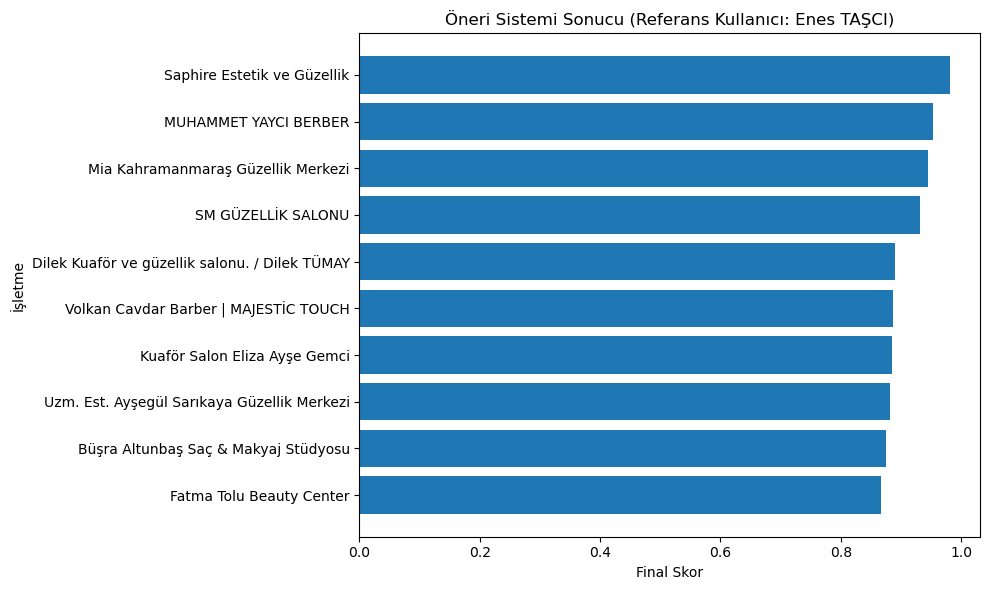

In [30]:
# =====================================================
# 12) GRAFİK
# =====================================================
top = final_table.head(10).copy()

plt.figure(figsize=(10, 6))
plt.barh(top["Isletme Adi"], top["Final_Skor"])
plt.xlabel("Final Skor")
plt.ylabel("İşletme")
plt.title(f"Öneri Sistemi Sonucu (Referans Kullanıcı: {REFERANS_USER})")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [31]:
# =====================================================
# 13) KAYDET
# =====================================================
final_table.to_csv("final_oneri_sonuc.csv", index=False, sep=";", encoding="utf-8-sig")
print("✅ Kaydedildi: final_oneri_sonuc.csv")

✅ Kaydedildi: final_oneri_sonuc.csv
